In [1]:
import geopandas as gpd
import numpy as np
import rasterio
from rasterstats import zonal_stats
import glob
import pandas as pd
import os
from datetime import datetime
import re
import matplotlib.pyplot as plt
from exactextract import exact_extract

In [ ]:
# OUTPUT_DIR_NAME = "Output"
# MERGED_OUTPUT_NAME = "wijk_alle_bomen_gecombineerd.gpkg"

# # Pad instellen
# # script_dir = os.path.dirname(os.path.abspath(__file__))
# output_dir = "Output\\"  # os.path.join(script_dir, OUTPUT_DIR_NAME)

# # Zoek alle .gpkg bestanden in de outputmap
# gpkg_files = glob.glob(os.path.join(output_dir, "schildersbuurt*.gpkg"))

# # Filter het doelbestand zelf eruit als dat er toevallig al staat
# gpkg_files = [f for f in gpkg_files if os.path.basename(f) != MERGED_OUTPUT_NAME]

# if not gpkg_files:
#     print(f"Geen .gpkg bestanden gevonden in: {output_dir}")
# else:
#     print(f"Gevonden: {len(gpkg_files)} GeoPackage bestanden om samen te voegen.")
    
#     gdf_list = []
#     for file_path in gpkg_files:
#         try:
#             print(f"Inlezen: {os.path.basename(file_path)}")
#             gdf = gpd.read_file(file_path)
#             gdf_list.append(gdf)
#         except Exception as e:
#             print(f"Fout bij inlezen van {os.path.basename(file_path)}: {e}")

#     if gdf_list:
#         # Combineer alle GeoDataFrames in één grote GeoDataFrame
#         print("Bezig met samenvoegen...")
#         merged_gdf = pd.concat(gdf_list, ignore_index=True)
#          #Remove duplicates based on geometry and attributes if necessary
#         initial_count = len(merged_gdf)
#         merged_gdf = merged_gdf.drop_duplicates(subset=['geometry'])
            
#         # Optie B (optioneel): Als polygonen net een mini-verschil hebben door tegelgrenzen,
#         # kun je op basis van de centroids (middelpunten) met een kleine tolerantie filteren:
#         merged_gdf['centroid'] = merged_gdf.geometry.centroid
#         merged_gdf = merged_gdf.drop_duplicates(subset=['centroid'])
#         merged_gdf = merged_gdf.drop(columns=['centroid'])
            
#         print(f"Dubbele bomen verwijderd: {initial_count - len(merged_gdf)} bomen samengevoegd/gewist.")
#         # Opslaan als één nieuw bestand
#         merged_output_path = os.path.join(output_dir, MERGED_OUTPUT_NAME)
#         merged_gdf.to_file(merged_output_path, driver="GPKG")
        
#         print("\n" + "="*40)
#         print(f" Klaar! Alle bestanden succesvol samengevoegd.")
#         print(f" Totaal aantal objecten (bomen): {len(merged_gdf)}")
#         print(f" Opgeslagen als: {merged_output_path}")
#         print("="*40)
#     else:
#         print("Geen geldige data gevonden om samen te voegen.")

Gevonden: 5 GeoPackage bestanden om samen te voegen.
Inlezen: schildersbuurt1_2.5_1.5_3_polygons.gpkg
Inlezen: schildersbuurt2_2.5_1.5_3_polygons.gpkg
Inlezen: schildersbuurt3_2.5_1.5_3_polygons.gpkg
Inlezen: schildersbuurt4_2.5_1.5_3_polygons.gpkg
Inlezen: schildersbuurt5_2.5_1.5_3_polygons.gpkg
Bezig met samenvoegen...


C:\Users\hoeks\AppData\Local\Temp\ipykernel_11460\1822250788.py:31: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  merged_gdf = pd.concat(gdf_list, ignore_index=True)


Dubbele bomen verwijderd: 54 bomen samengevoegd/gewist.

 Klaar! Alle bestanden succesvol samengevoegd.
 Totaal aantal objecten (bomen): 3553
 Opgeslagen als: Output\wijk_alle_bomen_gecombineerd.gpkg


In [4]:
grid_path = "C:\\Floor\\Documenten\\ENV-year-2\\Thesis\\Data\\Duindorp\\duindorp_grid_extent.gpkg"
grid = gpd.read_file(grid_path)

grid["grid_id"] = grid.index

# ============================
# Add shadow features
# ============================

groene_schaduw = "C:\\Floor\\Documenten\\ENV-year-2\\Thesis\\Data\\groene_schaduw_2025_2.tif"
grijze_schaduw = "C:\\Floor\\Documenten\\ENV-year-2\\Thesis\\Data\\grijze_schaduw_2025_2.tif"
combined_schaduw = "C:\\Floor\\Documenten\\ENV-year-2\\Thesis\\Data\\schaduwkaart.tif"

with rasterio.open(groene_schaduw) as src:
    raster_crs = src.crs
if grid.crs != raster_crs:
    print("CRS of grid and raster do not match. Reprojecting grid to match raster CRS.")
    grid = grid.to_crs(raster_crs)

green_shadow_stats = exact_extract(groene_schaduw, grid, ['sum', 'count'], output = "pandas")
green_shadow_stats["percentage_green_shadow"] = np.round((green_shadow_stats["sum"] / green_shadow_stats["count"]) * 100, 2)

grey_shadow_stats = exact_extract(grijze_schaduw, grid, ['sum', 'count'], output = "pandas")
grey_shadow_stats["percentage_grey_shadow"] = np.round((grey_shadow_stats["sum"] / grey_shadow_stats["count"]) * 100, 2)

combined_shadow_stats = exact_extract(combined_schaduw, grid, ['sum', 'count'], output = "pandas")
combined_shadow_stats["percentage_combined_shadow"] = np.round((combined_shadow_stats["sum"] / combined_shadow_stats["count"]) * 100, 2)

grid["percentage_green_shadow"] = green_shadow_stats["percentage_green_shadow"]
grid["percentage_grey_shadow"] = grey_shadow_stats["percentage_grey_shadow"]
grid["percentage_combined_shadow"] = combined_shadow_stats["percentage_combined_shadow"]

print("Shadow features added to the grid.")

# ============================
# Add tree features to grid
# ============================

trees = gpd.read_file("C:\\Floor\\Documenten\\ENV-year-2\\Thesis\\Data\\Duindorp\\Duindorp_alle_bomen_2.5_1.5_3.gpkg")

if trees.crs != grid.crs:
    trees = trees.to_crs(grid.crs)

trees["orig_area"] = trees.geometry.area

intersection = gpd.overlay(trees, grid, how='intersection')
intersection["clipped_area"] = intersection.geometry.area
intersection["area_ratio"] = intersection["clipped_area"] / intersection["orig_area"]

intersection["boomkroonvolume_m3"] = np.round(intersection["measured_cv_m3"] * intersection["area_ratio"], 2)
intersection["boomkroonoppervlakte_m2"] = np.round(intersection['measured_ca_m2'] * intersection['area_ratio'], 2)
intersection["biomassa_bermudez_kg"] = np.round(intersection['model_agb_kg_bermudez'] * intersection['area_ratio'], 2)

trees_sum = intersection.groupby("grid_id")[["boomkroonvolume_m3", "boomkroonoppervlakte_m2", "biomassa_bermudez_kg"]].sum().reset_index()

grid = grid.merge(trees_sum, on="grid_id", how="left")
grid["boomkroonvolume_m3"] = grid["boomkroonvolume_m3"].fillna(0)
grid["boomkroonoppervlakte_m2"] = grid["boomkroonoppervlakte_m2"].fillna(0)
grid["biomassa_bermudez_kg"] = grid["biomassa_bermudez_kg"].fillna(0)

print("Tree features added to the grid.")

# ============================
# Add ECOSTRESS temperature data to the grid
# ============================

temp_data_folder = "C:\\Floor\\Documenten\\ENV-year-2\\Thesis\\Data\\ECOSTRESS\\ECOSTRESS_sharp\\sharp\\"

tif_files = sorted(glob.glob(os.path.join(temp_data_folder, "*.tif")))

with rasterio.open(tif_files[0]) as src:
    raster_crs = src.crs

if grid.crs != raster_crs:
    print("CRS of grid and raster do not match. Reprojecting grid to match raster CRS.")
    grid = grid.to_crs(raster_crs)

centroids = [(geom.centroid.x, geom.centroid.y) for geom in grid.geometry]

for i, tif_path in enumerate(tif_files, 1):
    filename = os.path.basename(tif_path)

    # Bepaal kolomnaam op basis van datum/tijd (bijv. LST_20250602T135437)
    match = re.search(r"\d{8}T\d{6}", filename)
    if match:
        dt = datetime.strptime(match.group(0), "%Y%m%dT%H%M%S")
        col_name = f"LST_{dt.strftime('%Y-%m-%d %H:%M')}"
    else:
        col_name = f"LST_{i}"

    print(f"[{i}/{len(tif_files)}] Verwerken: {col_name}...")

    with rasterio.open(tif_path) as src:
        # Sample de pixelwaarden op de centroid-locaties
        sampled_values = [val[0] for val in src.sample(centroids)]
        nodata_val = src.nodata

        celsius_list = []
        for val in sampled_values:
            # Sla NoData / ongeldige waarden over
            if (
                val is None
                or (nodata_val is not None and val == nodata_val)
                or np.isnan(val)
            ):
                celsius_list.append(None)
            else:
                # Omrekenen van Kelvin naar Celsius
                celsius_list.append(round(val - 273.15, 2))

        # Voeg toe als nieuwe kolom aan het dataframe
        grid[col_name] = celsius_list      

print("ECOSTRESS temperature data added to the grid.")

# ============================
# Save the final grid with all features
# ============================

output_path = "C:\\Floor\\Documenten\\ENV-year-2\\Thesis\\Data\\master_grid_with_features.gpkg"
grid.to_file(output_path, driver="GPKG")

print(f"Final grid with features saved to {output_path}")

CRS of grid and raster do not match. Reprojecting grid to match raster CRS.
Shadow features added to the grid.
Tree features added to the grid.
CRS of grid and raster do not match. Reprojecting grid to match raster CRS.
[1/31] Verwerken: LST_2025-06-02 13:54...
[2/31] Verwerken: LST_2025-06-02 15:30...
[3/31] Verwerken: LST_2025-06-03 13:05...
[4/31] Verwerken: LST_2025-06-04 12:18...
[5/31] Verwerken: LST_2025-06-05 13:06...
[6/31] Verwerken: LST_2025-06-06 12:17...
[7/31] Verwerken: LST_2025-06-09 11:29...
[8/31] Verwerken: LST_2025-06-11 11:29...
[9/31] Verwerken: LST_2025-06-12 09:04...
[10/31] Verwerken: LST_2025-06-15 09:51...
[11/31] Verwerken: LST_2025-06-16 09:03...
[12/31] Verwerken: LST_2025-06-18 07:26...
[13/31] Verwerken: LST_2025-06-29 04:58...
[14/31] Verwerken: LST_2025-06-30 04:10...
[15/31] Verwerken: LST_2025-07-10 22:26...
[16/31] Verwerken: LST_2025-07-11 21:37...
[17/31] Verwerken: LST_2025-07-25 16:45...
[18/31] Verwerken: LST_2025-07-30 15:55...
[19/31] Verwerk

Correlation matrix between tree features and temperature data:
                      boomkroonvolume_m3  LST_2025-06-02 13:54  \
boomkroonvolume_m3              1.000000             -0.327444   
LST_2025-06-02 13:54           -0.327444              1.000000   
LST_2025-06-02 15:30           -0.198388              0.649276   
LST_2025-06-03 13:05           -0.210649              0.411294   
LST_2025-06-04 12:18           -0.295577              0.563201   
LST_2025-06-05 13:06           -0.025215             -0.058976   
LST_2025-06-06 12:17           -0.177196              0.562307   
LST_2025-06-09 11:29           -0.232746              0.515674   
LST_2025-06-11 11:29           -0.298934              0.693687   
LST_2025-06-12 09:04           -0.159099              0.503070   
LST_2025-06-15 09:51            0.017350              0.106596   
LST_2025-06-16 09:03           -0.269428              0.639117   
LST_2025-06-18 07:26           -0.239715              0.451079   
LST_2025-06-2

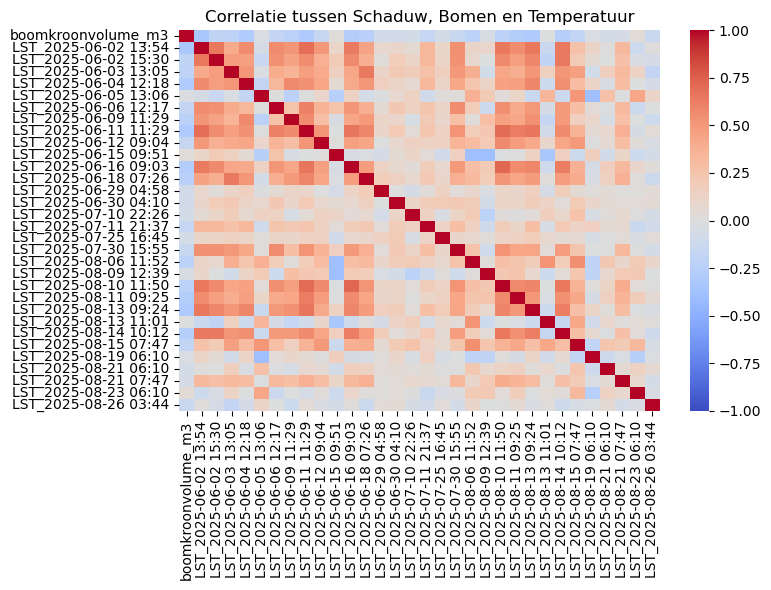

In [3]:
master_grid = gpd.read_file("C:\\Floor\\Documenten\\ENV-year-2\\Thesis\\Data\\Schildersbuurt\\master_grid_schildersbuurt.gpkg")

# columns_to_check = ["boomkroonvolume_m3", "boomkroonoppervlakte_m2", "biomassa_bermudez_kg", 
                    # "percentage_green_shadow", "percentage_grey_shadow", "percentage_combined_shadow"]
columns_to_check = ["boomkroonvolume_m3"]

# all columns starting with LST_
columns_to_check += [col for col in master_grid.columns if col.startswith("LST_")]

df_stats = master_grid[columns_to_check]
correlation_matrix = df_stats.corr(method='pearson')

print("Correlation matrix between tree features and temperature data:")
print(correlation_matrix)

import seaborn as sns
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=False, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlatie tussen Schaduw, Bomen en Temperatuur")
plt.tight_layout()
plt.show()

In [4]:
import statsmodels.api as sm

# 1. Kies je afhankelijke variabele (bijv. een specifieke LST middagmeting)
y = master_grid["LST_2025-06-02 13:54"]

# 2. Kies je voorspellers (bomen en schaduw)
X = master_grid["boomkroonvolume_m3"]

# 3. Voeg een constante toe (intercept)
X = sm.add_constant(X)

# Verwijder eventuele rijen met ontbrekende waardes (NaN) om fouten te voorkomen
data_for_reg = pd.concat([y, X], axis=1).dropna()
y_clean = data_for_reg[y.name]
X_clean = data_for_reg[X.columns]

# 4. Draai het regressiemodel
model = sm.OLS(y_clean, X_clean).fit()

# 5. Print de resultaten
print(model.summary())

                             OLS Regression Results                             
Dep. Variable:     LST_2025-06-02 13:54   R-squared:                       0.107
Model:                              OLS   Adj. R-squared:                  0.107
Method:                   Least Squares   F-statistic:                     466.5
Date:                  Fri, 16 Oct 2026   Prob (F-statistic):           8.65e-98
Time:                          10:42:53   Log-Likelihood:                -5446.1
No. Observations:                  3886   AIC:                         1.090e+04
Df Residuals:                      3884   BIC:                         1.091e+04
Df Model:                             1                                         
Covariance Type:              nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const           

               Tijdstip  Coefficient (Effect per m3)      P-waarde  R-squared
0  LST_2025-06-02 13:54                    -0.016156  7.757639e-70   0.077212
1  LST_2025-06-02 15:30                    -0.009725  6.093593e-26   0.028163
2  LST_2025-06-03 13:05                    -0.012945  8.700331e-37   0.040492
3  LST_2025-06-04 12:18                    -0.024382  1.267436e-85   0.094278
4  LST_2025-06-05 13:06                    -0.000571  8.745254e-01   0.000007
5  LST_2025-06-06 12:17                    -0.009705  6.833901e-17   0.017793
6  LST_2025-07-25 16:45                    -0.024183  8.298570e-07   0.006335
7  LST_2025-07-30 15:55                    -0.006504  6.455759e-17   0.017821
8  LST_2025-08-09 12:39                    -0.004287  7.785181e-02   0.000800


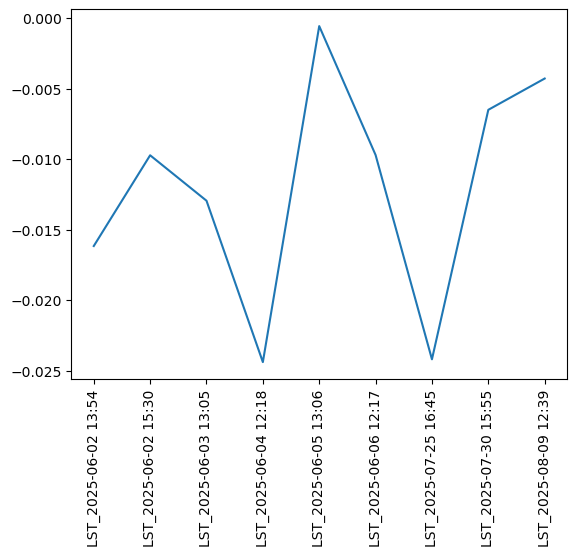

In [5]:
lst_columns = [col for col in master_grid.columns if col.startswith("LST_")]

#split the lst files into morning and afternoon based on the time in the column name
morning_columns = [col for col in lst_columns if "06:" in col or "07:" in col or"08:" in col or "09:" in col or "10:" in col or "11:" in col]
afternoon_columns = [col for col in lst_columns if "12:" in col or "13:" in col or "14:" in col or "15:" in col or "16:" in col or "17:" in col]
evening_columns = [col for col in lst_columns if "18:" in col or "19:" in col or "20:" in col or "21:" in col or "22:" in col or "23:" in col]
night_columns = [col for col in lst_columns if "00:" in col or "01:" in col or "02:" in col or "03:" in col or "04:" in col or "05:" in col]

results_list = []

for col in afternoon_columns:
    # Definieer y (specifieke LST) en X (boomkroonvolume)
    y = master_grid[col]
    X = master_grid[["percentage_green_shadow"]]
    X = sm.add_constant(X)
    
    # Opschonen van NaN waarden
    data_for_reg = pd.concat([y, X], axis=1).dropna()
    if len(data_for_reg) < 10:  # Te weinig data om te fitten
        continue
        
    y_clean = data_for_reg[y.name]
    X_clean = data_for_reg[X.columns]
    
    # Fit model
    model = sm.OLS(y_clean, X_clean).fit()
    
    # Sla resultaten op
    results_list.append({
        "Tijdstip": col,
        "Coefficient (Effect per m3)": model.params["percentage_green_shadow"],
        "P-waarde": model.pvalues["percentage_green_shadow"],
        "R-squared": model.rsquared
    })

# Maak er een net overzicht van in een DataFrame
df_results = pd.DataFrame(results_list)
print(df_results)

plt.plot(df_results["Tijdstip"], df_results["Coefficient (Effect per m3)"])
plt.tick_params(axis='x', rotation=90)